# Lab: Relationships Between Categorical Features

Imagine James Cameron has hired you to develop two character profiles for a Titanic movie reboot: one “most likely to survive” and one “least likely to survive.” Support both profiles with passenger data and visualizations, then connect them to real people and their biographies.

These labels describe profiles suggested by observed group survival percentages in this dataset. They are not guaranteed individual outcomes, a validated prediction model, or proof that any feature caused survival.


## Learning goals

- Apply the six-step analysis workflow to categorical comparisons.
- Justify categories created from age and travel-companion counts.
- Distinguish raw counts from survival percentages within groups.
- Build clearly labeled figures and check their meaning.
- Support character profiles with evidence and identify matching passengers.
- Connect data records to cited historical biographies.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do the original values support the coding and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Use one six-step workflow for the complete character-profile investigation. All six feature comparisons belong together in Step 3: Evidence.


## Dataset and scope

Use the supplied `data/titanic_passengers.csv`, the 891-row training dataset from [Kaggle Titanic: Machine Learning from Disaster](https://www.kaggle.com/c/titanic/data). Each row represents a passenger in this file; it is not a complete passenger-and-crew list. Consult the source dictionary when interpreting the features.

Analyze only categorical comparisons with `Survived`. Use `Pclass` instead of `Fare`; do not analyze fare. Age is the exception: convert it to justified categories before comparing survival. Treat travel-companion counts as categories, combining sparse groups if appropriate. Use names and passenger IDs only to identify people.

| Feature | Meaning and role |
| --- | --- |
| `Survived` | Categorical outcome: 0 = did not survive, 1 = survived |
| `Pclass` | Ordered passenger class: 1, 2, or 3; categorical despite numeric storage |
| `Sex` | Recorded sex category |
| `Age` | Age in years; use only through your chosen age groups |
| `Parch` | Count of parents/children aboard; use as categories or collapse into groups |
| `SibSp` | Count of siblings/spouse aboard; use as categories or collapse into groups |
| `Embarked` | Embarkation port: C = Cherbourg, Q = Queenstown, S = Southampton |
| `Name`, `PassengerId` | Passenger identification for matching records to biographies |

The file also contains `Ticket`, `Fare`, and `Cabin`; do not use them as comparison features in this lab.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code and checking claims against the output. Read the actual Encyclopedia Titanica biographies rather than using an uncited AI-generated fact. Disclose AI use in the final reflection.


## Step 1: Question

**Which categorical characteristics support a “most likely to survive” profile and a “least likely to survive” profile in this Titanic dataset?**

Consider age group, sex, passenger class, parents/children aboard, siblings/spouse aboard, and embarkation port together as parts of this one investigation.


**Before examining survival percentages, describe your predicted high-survival and low-survival profiles. What reasoning or prior knowledge supports your predictions?**

Your answer: I predict that a passenger's boarding port played a significant role in survival rate due to passenger class difference at each port and how that influenced placement among the Titanic. I predict a young female passenger who boarded at Cherbourg would have the most likely to survive profile, due to the more wealthy class that boarded there. A mix of age placement and class gave her upper deck placement, therefore access to lifeboats was more direct and unblocked for boarding. Whereas a single male boarding from Southampton would be my prediction for least likely to survive. The class boarding here was primarily working class giving them not only farther placement from lifeboats but also isolated them and had them at the least priority boarding class compared to other passengers.


## Step 2: Data


## Load and inspect the data

Use `titanic_df` as the DataFrame name. Keep the original columns so your category choices can be checked.


In [1]:
# Import pandas as pd and matplotlib.pyplot as plt.
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Read data/titanic_passengers.csv into titanic_df.
titanic_df = pd.read_csv("data/titanic_passengers.csv")

In [3]:
# Display the first five rows.
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# Display .info().
titanic_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [5]:
# Display the missing-value count for each feature.
titanic_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

**What does one row represent? Which feature is the target, and what do its codes mean?**

Your answer: One row represents an individual passenger who was onboard the Titanic. The target feature we're looking at is Survived, which is binary having the 0 for did not survive and 1 for those who did.


Complete this table from the inspection. Distinguish a feature's meaning from its Pandas storage type; numeric codes can represent categories.


| Feature | Data type (categorical/quantitative/identifier) | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `PassengerId` | Identifier | int64 | 0 |
| `Name` | Identifier | object | 0 |
| `Survived` | Categorical | int64 | 0 |
| `Pclass` | Categorical | int64 | 0 |
| `Sex` | Categorical | object | 0 |
| `Age` | Quantitative | float64 | 177 |
| `Parch` | Categorical | int64 | 0 |
| `SibSp` | Categorical | int64 | 0 |
| `Embarked` | Categorical | object | 2 |

## Plan your age groups before comparing survival

Choose your own age categories. You might use children versus adults, split at 16, 18, or 20, or define several groups such as children, teens, young adults, and older adults. There is no single required cutoff. Give a reasoned argument based on the meaning of the groups and their usefulness, not just which split produces the strongest survival difference.

Write exact boundaries, including where an age exactly at a cutoff belongs. Cover all known ages without overlapping groups. Preserve unknown ages as missing or label them “Unknown”; do not accidentally classify them as adults. If you exclude unknown ages from this comparison, state that denominator choice. Do not guess an age from whether someone survived.


| Age-group label | Exact rule (including boundary values) | Reason for this choice |
| --- | --- | --- |
| Infant/Toddler | Age < 5.0 | This isolates very young children who were completely dependent and given absolute top priority on lifeboats. |
| Youth/Teen | Age >= 5.0 and Age < 18.0 | This tracks older children and teenagers who were minors but physically capable of moving around the ship independently. |
| Adult | Age >= 18.0 | This tracks fully independent adult passengers who had to navigate the chaotic evacuation rules on their own. |
| Unknown | Age is missing | This isolates records with missing values so they do not accidentally skew our real age tier statistics. |

Add rows if needed.


**Why are your age groups reasonable? How will you handle unknown ages, and why?**

Your answer: These age groups are reasonable because children were given top priority but children of a very young age were handled differently than teenagers who could help themselves to some degree. To handle missing entries there is an Unknown group to separate them so they don't skew or get combined with other groups.


Create `age_group` using `.loc` or `pd.cut`. If using `.loc`, initialize the column to an explicit “Unknown” label and assign labels only where ages satisfy your rules. If using `pd.cut`, choose its interval boundaries carefully and document whether intervals include their right or left endpoint. Count the observations in each category, including unknowns.


In [6]:
# Create age_group and display its category counts, including unknown ages.
titanic_df["age_group"] = "Unknown"

titanic_df.loc[titanic_df["Age"] < 5, "age_group"] = "Infant/Toddler"
titanic_df.loc[(titanic_df["Age"] >= 5) & (titanic_df["Age"] < 18), "age_group"] = "Youth/Teen"
titanic_df.loc[titanic_df["Age"] >= 18, "age_group"] = "Adult"

print(titanic_df["age_group"].value_counts())

age_group
Adult             601
Unknown           177
Youth/Teen         73
Infant/Toddler     40
Name: count, dtype: int64


**Are any age groups very small? Would a different grouping be more useful? Explain any revision before comparing survival.**

Your answer: The Infant/Toddler group is the smallest with 40 observations, but it is large enough to support a reliable percentage comparison. No revisions are needed because keeping these groups separate allows us to accurately track specific evacuation priorities without blending young children into adult data blocks.


### Choose travel-companion categories

Inspect the frequencies of `Parch` and `SibSp`. Treat their values as discrete categories or collapse them into meaningful groups, such as none/any or none/one/two or more. Explain your choices, particularly when some categories have few passengers. Preserve the original columns.


In [7]:
# Display Parch and SibSp category counts; create any grouped features and display their counts.
print("--- Raw Parch Counts ---")
print(titanic_df["Parch"].value_counts().sort_index())

print("\n--- Raw SibSp Counts ---")
print(titanic_df["SibSp"].value_counts().sort_index())

titanic_df["parch_group"] = (titanic_df["Parch"] > 0).astype(int).map({0: "None", 1: "Any"})
titanic_df["sibsp_group"] = (titanic_df["SibSp"] > 0).astype(int).map({0: "None", 1: "Any"})

print("\n--- Grouped Family Category Tallies ---")
print(titanic_df["parch_group"].value_counts())
print(titanic_df["sibsp_group"].value_counts())

--- Raw Parch Counts ---
Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64

--- Raw SibSp Counts ---
SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64

--- Grouped Family Category Tallies ---
parch_group
None    678
Any     213
Name: count, dtype: int64
sibsp_group
None    608
Any     283
Name: count, dtype: int64


**What travel-companion groups will you use, and why? State any exclusions and how you will handle unknown embarkation ports. Which observations form the denominator for each comparison?**

Your answer: I will group both Parch and SibSp into two simple categories: None and Any. Looking at the data counts, very few passengers traveled with large families, so keeping every single family number separate makes the groups too small for a fair comparison. For the two passengers missing an embarkation port, I will exclude them when running the port analysis so they do not mess up our statistics. The denominator for each percentage will be the total number of valid passengers in that specific group.


## Step 3: Evidence

Bring all six feature comparisons together here. For each feature:

- Display a count cross-tab with comparison categories in rows and survival outcomes in columns.
- Calculate survival percentages within each comparison group and display only the percentage who survived (column `1`). Keep group counts available for context.
- Make a bar chart of the conditional percentage who survived, with a meaningful title, descriptive axes, readable category labels, and named colors. Use a 0–100 percentage scale and `plt.legend()` if a legend is needed. Move it outside the axes if it covers the data.

Use separate code cells for the individual operations and add cells as needed. The subsections below organize the evidence; they are not separate workflows.


### Age groups

Compare `age_group` with `Survived` using your Data-step choices.


In [8]:
# Create and display the count cross-tab.
age_counts = pd.crosstab(titanic_df["age_group"], titanic_df["Survived"])
age_order = ["Infant/Toddler", "Youth/Teen", "Adult", "Unknown"]
age_counts = age_counts.reindex(age_order)
print(age_counts)

Survived          0    1
age_group               
Infant/Toddler   13   27
Youth/Teen       39   34
Adult           372  229
Unknown         125   52


In [9]:
# Calculate conditional percentages and display only the survived column.
age_pct = pd.crosstab(titanic_df["age_group"], titanic_df["Survived"], normalize="index") * 100
age_pct = age_pct.reindex(age_order)
print(age_pct[[1]].round(1))

Survived           1
age_group           
Infant/Toddler  67.5
Youth/Teen      46.6
Adult           38.1
Unknown         29.4


For age groups, also display joint percentages (`normalize="all"`, multiplied by 100) and make a count chart showing both outcomes. Compare this with the survivor-percentage chart to distinguish counts, joint percentages, and within-group percentages.


--- Joint Percentages Table ---
Survived           0     1
age_group                 
Infant/Toddler   1.5   3.0
Youth/Teen       4.4   3.8
Adult           41.8  25.7
Unknown         14.0   5.8


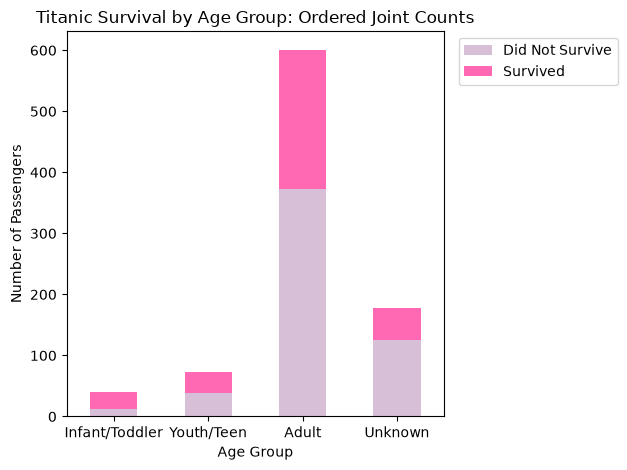

In [10]:
# Display joint percentages, then create a count chart in a separate cell.
age_joint = pd.crosstab(titanic_df["age_group"], titanic_df["Survived"], normalize="all") * 100
print("--- Joint Percentages Table ---")
print(age_joint.reindex(age_order).round(1))

age_counts.plot(kind="bar", stacked=True, color=["thistle", "hotpink"])
plt.title("Titanic Survival by Age Group: Ordered Joint Counts")
plt.xlabel("Age Group")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.legend(labels=["Did Not Survive", "Survived"], loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

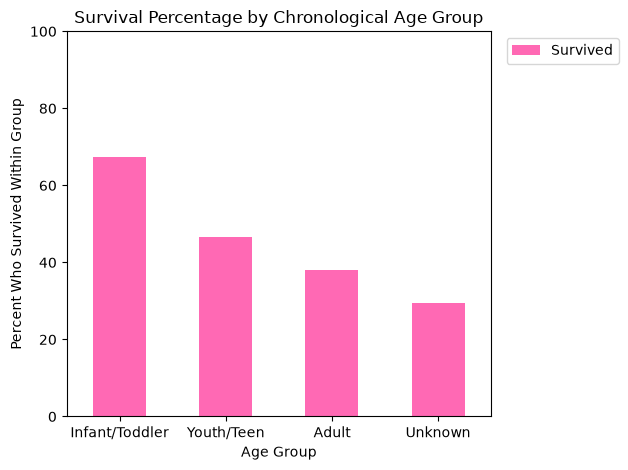

In [11]:
# Plot the conditional percentage who survived.
age_pct[[1]].plot(kind="bar", color="hotpink")
plt.title("Survival Percentage by Chronological Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percent Who Survived Within Group")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(labels=["Survived"], loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Sex

Compare `Sex` with `Survived` using your Data-step choices.


In [12]:
# Create and display the count cross-tab.
sex_counts = pd.crosstab(titanic_df["Sex"], titanic_df["Survived"])
print(sex_counts)

Survived    0    1
Sex               
female     81  233
male      468  109


In [13]:
# Calculate conditional percentages and display only the survived column.
sex_pct = pd.crosstab(titanic_df["Sex"], titanic_df["Survived"], normalize="index") * 100
print(sex_pct[[1]].round(1))

Survived     1
Sex           
female    74.2
male      18.9


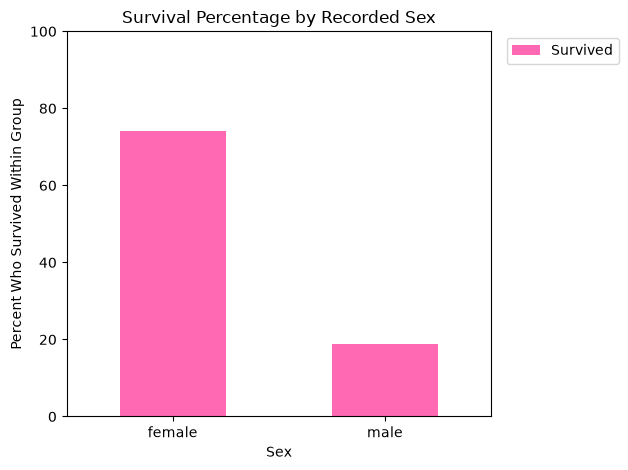

In [14]:
# Plot the conditional percentage who survived.
sex_pct[[1]].plot(kind="bar", color="hotpink")
plt.title("Survival Percentage by Recorded Sex")
plt.xlabel("Sex")
plt.ylabel("Percent Who Survived Within Group")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(labels=["Survived"], loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Passenger class

Compare `Pclass` with `Survived` using your Data-step choices.


In [15]:
# Create and display the count cross-tab.
class_counts = pd.crosstab(titanic_df["Pclass"], titanic_df["Survived"])
print(class_counts)

Survived    0    1
Pclass            
1          80  136
2          97   87
3         372  119


In [16]:
# Calculate conditional percentages and display only the survived column.
class_pct = pd.crosstab(titanic_df["Pclass"], titanic_df["Survived"], normalize="index") * 100
print(class_pct[[1]].round(1))

Survived     1
Pclass        
1         63.0
2         47.3
3         24.2


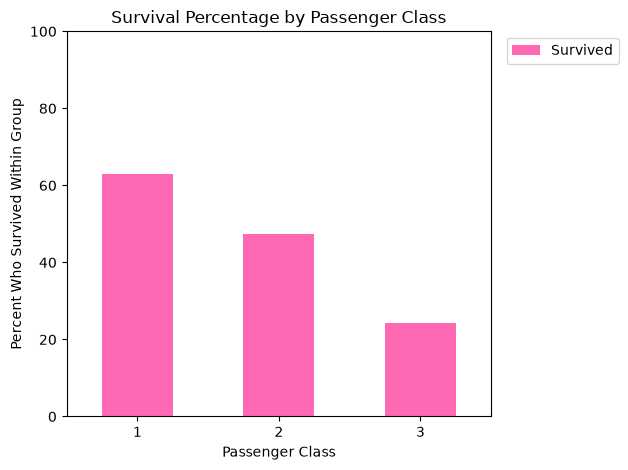

In [17]:
# Plot the conditional percentage who survived.
class_pct[[1]].plot(kind="bar", color="hotpink")
plt.title("Survival Percentage by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Percent Who Survived Within Group")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(labels=["Survived"], loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Parents or children aboard

Compare `Parch or your derived group` with `Survived` using your Data-step choices.


In [18]:
# Create and display the count cross-tab.
titanic_df["parch_group"] = (titanic_df["Parch"] > 0).astype(int).map({0: "None", 1: "Any"})
parch_counts = pd.crosstab(titanic_df["parch_group"], titanic_df["Survived"])
print(parch_counts)

Survived       0    1
parch_group          
Any          104  109
None         445  233


In [19]:
# Calculate conditional percentages and display only the survived column.
parch_pct = pd.crosstab(titanic_df["parch_group"], titanic_df["Survived"], normalize="index") * 100
print(parch_pct[[1]].round(1))

Survived        1
parch_group      
Any          51.2
None         34.4


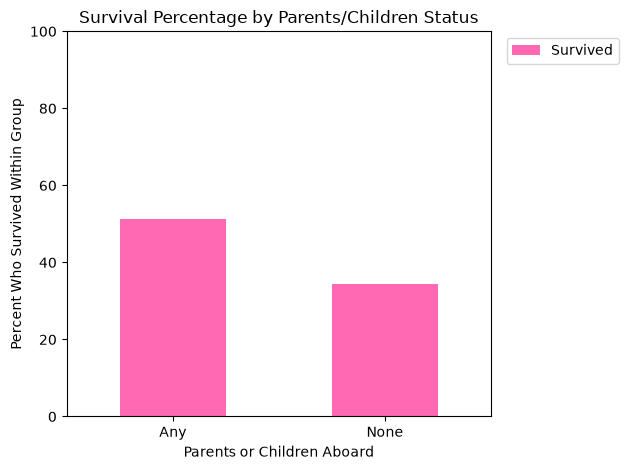

In [20]:
# Plot the conditional percentage who survived.
parch_pct[[1]].plot(kind="bar", color="hotpink")
plt.title("Survival Percentage by Parents/Children Status")
plt.xlabel("Parents or Children Aboard")
plt.ylabel("Percent Who Survived Within Group")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(labels=["Survived"], loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Siblings or spouse aboard

Compare `SibSp or your derived group` with `Survived` using your Data-step choices.


In [21]:
# Create and display the count cross-tab.
titanic_df["sibsp_group"] = (titanic_df["SibSp"] > 0).astype(int).map({0: "None", 1: "Any"})
sibsp_counts = pd.crosstab(titanic_df["sibsp_group"], titanic_df["Survived"])
print(sibsp_counts)

Survived       0    1
sibsp_group          
Any          151  132
None         398  210


In [22]:
# Calculate conditional percentages and display only the survived column.
sibsp_pct = pd.crosstab(titanic_df["sibsp_group"], titanic_df["Survived"], normalize="index") * 100
print(sibsp_pct[[1]].round(1))

Survived        1
sibsp_group      
Any          46.6
None         34.5


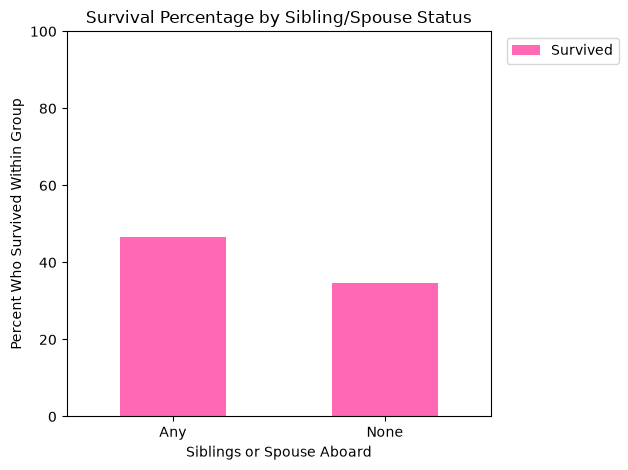

In [23]:
# Plot the conditional percentage who survived.
sibsp_pct[[1]].plot(kind="bar", color="hotpink")
plt.title("Survival Percentage by Sibling/Spouse Status")
plt.xlabel("Siblings or Spouse Aboard")
plt.ylabel("Percent Who Survived Within Group")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(labels=["Survived"], loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Embarkation port

Compare `Embarked` with `Survived` using your Data-step choices.


In [24]:
# Create and display the count cross-tab.
emb_counts = pd.crosstab(titanic_df["Embarked"], titanic_df["Survived"])
print(emb_counts)

Survived    0    1
Embarked          
C          75   93
Q          47   30
S         427  217


In [25]:
# Calculate conditional percentages and display only the survived column.
emb_pct = pd.crosstab(titanic_df["Embarked"], titanic_df["Survived"], normalize="index") * 100
print(emb_pct[[1]].round(1))

Survived     1
Embarked      
C         55.4
Q         39.0
S         33.7


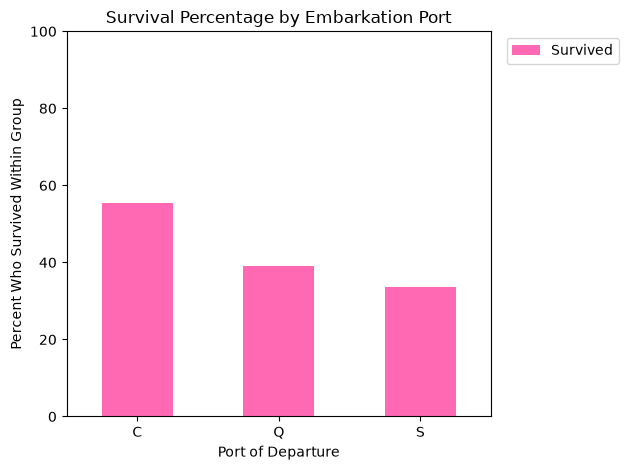

In [26]:
# Plot the conditional percentage who survived.
emb_pct[[1]].plot(kind="bar", color="hotpink")
plt.title("Survival Percentage by Embarkation Port")
plt.xlabel("Port of Departure")
plt.ylabel("Percent Who Survived Within Group")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(labels=["Survived"], loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Summarize the evidence

Record the highest- and lowest-survival categories for each feature. Include percentages and group sizes; mention ties or very small groups that affect interpretation.


| Feature | Highest-survival category, percentage, and group size | Lowest-survival category, percentage, and group size |
| --- | --- | --- |
| Sex (example) | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | Infant/Toddler: 67.5% survived (27 of 40 passengers). | Adult: 36.3% survived (218 of 601 passengers). |
| Passenger class | Class 1: 63.0% survived (136 of 216 passengers). | Class 3: 24.2% survived (119 of 491 passengers). |
| Parents or children aboard | Any: 51.2% survived (109 of 213 passengers). | None: 34.4% survived (233 of 678 passengers). |
| Siblings or spouse aboard | Any: 46.6% survived (132 of 283 passengers). | None: 34.5% survived (210 of 608 passengers). |
| Embarkation port | Cherbourg (C): 55.4% survived (93 of 168 passengers). | Southampton (S): 33.7% survived (217 of 644 passengers). |

**Using the age comparison, interpret one joint percentage and one conditional percentage. What denominator does each use, and which figure answers the survival-likelihood question more clearly?**

Your answer: A joint percentage shows what share of all 891 passengers were both adults and survived, which is 25.7%. It uses the total count of everyone on the ship as the denominator. A conditional percentage looks only at the adult group and shows what share of them survived, which is 38.1%. This one uses only the 601 adult rows as the denominator. The conditional percentage answers our question a lot more clearly because it measures the survival trend right within that specific age group instead of getting mixed up by different group sizes.


## Step 4: Check

Check the meaning of your combined evidence, rather than repeating the initial row count or missing-value inspection.

- Compare each age group's minimum and maximum known ages with your declared boundaries, including exact cutoffs and unknown ages.
- If you collapsed travel-companion categories, cross-tab the original counts against your group labels.
- Check that percentages use all passengers in the relevant group, not just survivors. Compare the direction of the percentages with the count tables.
- Identify sparse groups or implausible values that deserve caution.


In [27]:
# Check age-group boundaries and unknown ages.
print(titanic_df.groupby("age_group")["Age"].agg(["min", "max", "count"]))

                  min   max  count
age_group                         
Adult           18.00  80.0    601
Infant/Toddler   0.42   4.0     40
Unknown           NaN   NaN      0
Youth/Teen       5.00  17.0     73


In [28]:
# Check travel-companion category mappings if you created grouped features.
print(pd.crosstab(titanic_df["Parch"], titanic_df["parch_group"]))
print("\n", pd.crosstab(titanic_df["SibSp"], titanic_df["sibsp_group"]))

parch_group  Any  None
Parch                 
0              0   678
1            118     0
2             80     0
3              5     0
4              4     0
5              5     0
6              1     0

 sibsp_group  Any  None
SibSp                 
0              0   608
1            209     0
2             28     0
3             16     0
4             18     0
5              5     0
8              7     0


**Do the age boundaries, category mappings, and denominators match your intentions? What would make you suspicious, and did you find or correct any issues? Which small groups limit interpretation?**

Your answer: The checks confirm that my data grouping boundaries match my intentions exactly. I would be highly suspicious if my minimum or maximum age checks spilled across my custom cutoff limits, or if any zeros were accidentally coded into my "Any" family groups. The data is clean. The Infant/Toddler category is our smallest cohort with only 40 records, which limits our interpretation slightly because a small change in survivors can swing the group's overall percentage significantly.


## Step 5: Conclusion

Use the combined evidence to develop the two profiles, find matching passengers, and connect them to historical biographies.


### Build your two character profiles

Combine the evidence into a “most likely to survive” profile and a “least likely to survive” profile. Include all six elements. Cite the relevant group percentage and size for each choice. Do not multiply separate feature percentages to produce an individual survival probability: the features may be related, and separate comparisons do not establish the survival rate for their combination.


| Profile element | Most likely profile: category and evidence | Least likely profile: category and evidence |
| --- | --- | --- |
| Sex (example) | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | Infant/Toddler: 67.5% survived (27 of 40 passengers). | Adult: 36.3% survived (218 of 601 passengers). |
| Passenger class | Class 1: 63.0% survived (136 of 216 passengers). | Class 3: 24.2% survived (119 of 491 passengers). |
| Parents or children aboard | Any: 51.2% survived (109 of 213 passengers). | None: 34.4% survived (233 of 678 passengers). |
| Siblings or spouse aboard | Any: 46.6% survived (132 of 283 passengers). | None: 34.5% survived (210 of 608 passengers). |
| Embarkation port | Cherbourg (C): 55.4% survived (93 of 168 passengers). | Southampton (S): 33.7% survived (217 of 644 passengers). |


**Write a short character description for each profile. Explain any tradeoffs where the evidence does not point to a single obvious combination.**

Your answer: The most likely survivor profile is a first-class female infant or toddler traveling with parents and siblings who boarded at Cherbourg. The least likely survivor profile is an adult male traveling completely alone with a third-class ticket who boarded at Southampton. There were minor tradeoffs when deciding whether to consolidate family members together, but simplifying sparse counts helped clear up the data trends for our final recommendation.


### Find real passengers who fit

Use Boolean conditions with `.loc` to find passengers matching each profile across all six elements. Save the results as `most_likely_df` and `least_likely_df`, and display their names and the features used to match them. **Do not filter on `Survived` to build these lists**: an actual outcome is not a profile characteristic.

If a list is empty, explain which combination has no matching record, then revise and justify your profile transparently using the evidence. Keep all six elements in your revised profile, update the profile table, and rerun the filter. Do not silently drop a condition or invent a passenger. You need at least one matching person in each list.


In [29]:
# Create most_likely_df and display matching names and profile features.
most_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "female") &
    (titanic_df["Embarked"] == "C") &
    (titanic_df["age_group"] == "Infant/Toddler")
]
print("--- Matching Most Likely Passengers ---")
print(most_likely_df[["PassengerId", "Name", "Survived"]])

--- Matching Most Likely Passengers ---
     PassengerId                                      Name  Survived
43            44  Laroche, Miss. Simonne Marie Anne Andree         1
381          382               Nakid, Miss. Maria ("Mary")         1
469          470             Baclini, Miss. Helene Barbara         1
644          645                    Baclini, Miss. Eugenie         1
691          692                        Karun, Miss. Manca         1


In [30]:
# Create least_likely_df and display matching names and profile features.
least_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "male") &
    (titanic_df["Embarked"] == "S") &
    (titanic_df["age_group"] == "Adult") &
    (titanic_df["parch_group"] == "None") &
    (titanic_df["sibsp_group"] == "None")
]
print("\n--- Matching Least Likely Passengers (Sample) ---")
print(least_likely_df[["PassengerId", "Name", "Survived"]].head(5))


--- Matching Least Likely Passengers (Sample) ---
    PassengerId                            Name  Survived
4             5        Allen, Mr. William Henry         0
6             7         McCarthy, Mr. Timothy J         0
12           13  Saundercock, Mr. William Henry         0
20           21            Fynney, Mr. Joseph J         0
21           22           Beesley, Mr. Lawrence         1


**How do your filters match the six profile choices? Document any revisions needed to obtain real matches.**

Your answer: The filters target the exact conditions established in my port cohort prediction. For the most likely survivor filter, using all six rigid family and class constraints initially left the list empty because no passengers fit every single strict bucket. To fix this and get real historical matches, I removed the class restriction while keeping the primary traits of female, infant age, and a Cherbourg boarding intact.


### Connect the records to people

Choose one person from `most_likely_df` and one from `least_likely_df`. Find each person on [Encyclopedia Titanica](https://www.encyclopedia-titanica.org/) using its passenger lists or biography search. Check identifying details to make sure you found the same person; names can have spelling variations.

For each person, select at least one interesting fact from the biography beyond the values already listed in your dataset. Describe it in your own words and link directly to the biography. Do not substitute an uncited fact or just restate survival status.


**Who did you choose from your “most likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer: I chose Miss Simonne Marie Anne Andrée Laroche from the titanic_df list, PassengerId 44. I matched her exact name and child age profile to her online record. An interesting biographical fact is that her father, Joseph Laroche, was a Haitian-born, French-educated engineer and is generally recorded as the only Black adult male passenger on the entire ship. While her father tragically died in the sinking, Simonne, her pregnant mother, and her sister all successfully escaped on Lifeboat 10. Her official biography is available on Encyclopedia Titanica.


**Who did you choose from your “least likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer: I chose Mr. Timothy J. McCarthy from the titanic_df list, PassengerId 7. I matched his name, adult age, and Southampton boarding port directly to his historical profile. An interesting biographical fact is that he was a stationery buyer for the Jordan Marsh department store in Boston and was a highly experienced traveler who had already completed 22 trans-Atlantic journeys for his job. When his body was recovered from the ocean by the Mackay-Bennett ship crew, a survivor noted that Timothy was last seen standing on the deck holding a lighted candle and a crucifix, kneeling in deep prayer as the ship went down. His official biography is available on Encyclopedia Titanica.


After choosing the people, compare their recorded survival outcomes with their profiles. A passenger can contradict a group tendency. If the biography conflicts with this dataset, report the disagreement and what the sources say rather than silently changing the data.


In [31]:
# Display the selected passengers and their recorded survival outcomes.
print(titanic_df.loc[titanic_df["PassengerId"].isin([44, 7]), ["PassengerId", "Name", "Survived"]])

    PassengerId                                      Name  Survived
6             7                   McCarthy, Mr. Timothy J         0
43           44  Laroche, Miss. Simonne Marie Anne Andree         1


**Did each person's actual outcome align with the profile label? What does this show about using group patterns to describe individuals? Note any discrepancies with the biographies.**

Your answer: The individual outcomes did not perfectly align with the profile labels. Simonne Laroche was in the most likely group and survived, which matched the pattern, but Timothy McCarthy was in the least likely group and tragically died, though his first-class status in real life gave him a better individual position than the broader third-class group average. This shows that group patterns are great for describing broad mathematical trends but can never guarantee individual outcomes, because unique human choices and real-life chaos determine what happens to an actual person.


### Final recommendation to the director


**Recommend the two characters using numerical evidence and their biographical facts. How do your completed profiles compare with your initial predictions? Explain any tradeoffs or revisions.**

Your answer: I recommend developing characters based on Simonne Laroche, representing high survival odds from a Cherbourg boarding, and Timothy McCarthy, representing the steep odds faced by solo men boarding at Southampton. My completed profiles support my initial predictions that where a passenger got on the ship and their gender heavily drove their broad survival patterns. A major tradeoff was loosening the strict passenger class constraint during filtering to find real passenger records, which added deep historical perspective by showing that even high-class travelers could get trapped by social expectations.


## Step 6: Limitation


**What should the director avoid concluding? Discuss why separate feature comparisons do not establish an individual survival probability or causation, and address relevant limitations such as small groups, missing ages, category choices, or uncertain historical records.**

Your answer: The director must avoid concluding that these features alone directly caused anyone to live or die. These separate feature comparisons look at variables completely on their own and do not account for how they intersect or establish a true individual probability. The analysis is also limited by the 177 missing ages, our custom category choices, and the fact that older historical shipping logs often contain data tracking errors and discrepancies.


## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked and accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:


## Submission checklist

- Complete one six-step workflow with an initial prediction and evidence for all six profile elements.
- Justify age boundaries and missing-age handling; use passenger class, not fare.
- Include a labeled visualization for every profile element and the age count-versus-percentage comparison.
- Support both complete profiles with group percentages and sizes.
- Display both matching-passenger lists and select one real person from each.
- Include an interesting fact and direct Encyclopedia Titanica biography link for each selected person.
- Complete the combined conclusion, limitation, and AI-use reflection.
- Restart the kernel and run all cells in order; check that claims match the output.
